### Using Transfer learning and TensorFlow 2.0 to classify Different Dog Breeds

In this project we're going to be using machine learning to help us identify different breeds of dogs.

To do this, we'll be using data from the Kaggle data URL : https://www.kaggle.com/competitions/dog-breed-identification/data

It consists of a collection of 10,000_ labelled images of 120 dog breeds.

This kind of problem is called multi-class image classification. It's multi-class because we're trying to classify multiple different breeds of dog. If we were only trying to classify dogs VS cats, it would be called binary classification.

Multi-class image classification is an important problem because it's the same kind of technology Tesla uses in their self driving cars or Airbnb uses in automatically adding information to their listings.

Since the most important step in a deep learning problem is getting the data ready(turning it into numbers), that's what we're going to start with.

We're going to go through the following Tensorflow/Deep learning workflow:

1. Get data ready(download from Kaggle store, import)
2. Prepare the data(preprocessing, the 3 sets, X & Y).
3. Choose and fit/train a model.
4. Evaluating a model(making predictions, comparing them with the ground truth labels).
5. Improve the model through experimenation(start with 1000 images, make sure it works, increase the number of images)
6. Save, sharing and reloading your model.



## Getting the workspace ready


In [ ]:
# Use to extract from the data zip
# !unzip 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Data/dog-vision/dog-breed-identification.zip' -d "drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/"

In [7]:
import tensorflow as tf
print('TF Version: ', tf.__version__)

TF Version:  2.20.0


In [6]:
# import necessary tools
import tensorflow as tf
import tensorflow_hub as hub
import tf_keras as keras

print(f'TF Version: {tf.__version__}')
print(f'TF HUB Version: {hub.__version__}')
print(f'TF KERAS Versoin: {keras.__version__}')
# check for GPU availability
print(f'GPU {"Yes :)" if tf.config.list_physical_devices('GPU') else "NO :("}')

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TF Version: 2.20.0
TF HUB Version: 0.16.1
TF KERAS Versoin: 2.20.1
GPU Yes :)


## Getting our data ready(turning into tensors)



In [22]:
import pandas as pd
import numpy as np


labels_csv = pd.read_csv('drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/labels.csv')
labels_csv.head(10)


,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever
5,002211c81b498ef88e1b40b9abf84e1d,bedlington_terrier
6,00290d3e1fdd27226ba27a8ce248ce85,bedlington_terrier
7,002a283a315af96eaea0e28e7163b21b,borzoi
8,003df8b8a8b05244b1d920bb6cf451f9,basenji
9,0042188c895a2f14ef64a918ed9c7b64,scottish_deerhound


Mounted at /content/drive


Looking at the length of the data, we can see that there are 10222 rows and 120 breeds (unique breeds)

In [ ]:
len(labels_csv), len(labels_csv['breed'].unique())

(10222, 120)

<Axes: xlabel='breed'>

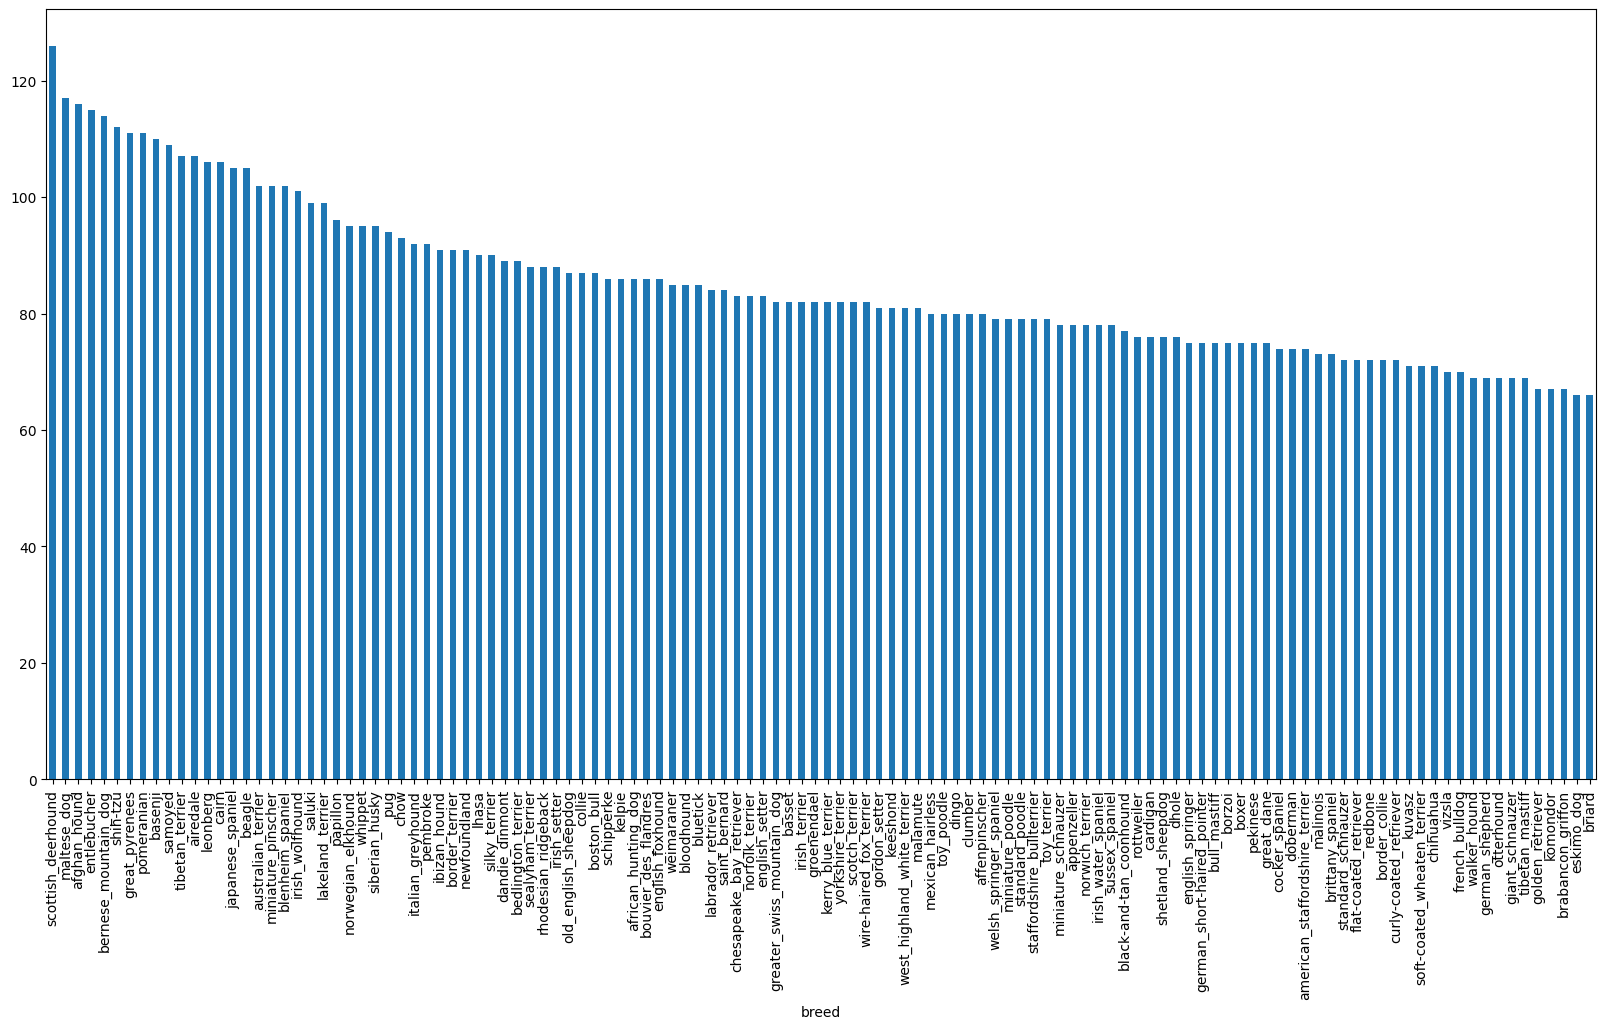

In [ ]:
labels_csv['breed'].value_counts().plot.bar(figsize=(20,10))

If we were to roughly draw a line across the middle of the graph, we'd see there are about 60+ images for each dog breed.

In [ ]:
labels_csv['breed'].value_counts().median()

82.0

In [ ]:
# Viewing a image in Colab
from IPython.display import display, Image
# display(Image(filename="drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/002a283a315af96eaea0e28e7163b21b.jpg"))

## Getting images and their labels

Since we've got the image ID's and their labels in a DF(labels_csv), we'll use it to create:

1. A list of filepaths to trainig images
2. An array of all labels
3. An Array of all unique labels

In [ ]:
TRAIN_FILE_PATH = 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/'
filenames = [TRAIN_FILE_PATH + filename + ".jpg" for filename in labels_csv['id']]
filenames[:10]

['drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/001cdf01b096e06d78e9e5112d419397.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/002a283a315af96eaea0e28e7163b21b.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/003df8b8a8b05244b1d920

In [ ]:
# check whether number of filenames matches the actual image files
import os
if len(os.listdir(TRAIN_FILE_PATH)) == len(filenames):
  print("Filenames match actual amount of files in training set")
else:
  print("Filenames do not match the training set, check the target directory")

Filenames match actual amount of files in training set


In [ ]:
# check an image directly from a filepath
Image(filenames[9000])

NameError: name 'Image' is not defined

Now that we've got our image filepaths together, let's get the labels.

We'll take them from the labels_csv and turn them into Numpy Array

In [24]:
import numpy as np
labels = labels_csv['breed'].to_numpy() # convert labels column to Numpy array
labels[:10]

array(['boston_bull', 'dingo', 'pekinese', 'bluetick', 'golden_retriever',
       'bedlington_terrier', 'bedlington_terrier', 'borzoi', 'basenji',
       'scottish_deerhound'], dtype=object)

In [ ]:
# see if number of labels mathces the number of filenames
if len(labels) == len(filenames):
  print("Number of labels matches the number of filenames")
else:
  print("Number of labels does not match the number of filenames")

Number of labels matches the number of filenames


Finally since a machine learning model cannot take strings as input, we'll have to conver our labels into numbers

To begin with find the unique dog breed names

Then we'll go through the list of labels and compare them to unique breeds and create a list of booleans indicating which one is the real label (True) and which ones aren't (False).


In [25]:
unique_breeds = np.unique(labels)
len(unique_breeds)

120

In [ ]:
# Turn one label into an array of booleans
print(labels[0])
labels[0] == unique_breeds

boston_bull


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [ ]:
# turn every label into boolean array
boolean_labels = [label == np.array(unique_breeds) for label in labels]
boolean_labels[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [ ]:
len(boolean_labels)

10222

In [ ]:
# Example turning boolean array into integers
print(labels[0]) # original label
print(np.where(unique_breeds == labels[0])) # index where label occurs
print(boolean_labels[0].argmax()) # index where label occurs in boolean array
print(boolean_labels[0].astype(int)) # there will be a 1 where the sample label occurs

boston_bull
(array([19]),)
19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


### creating our own validation set.


In [ ]:
# setup X and y variables
X = filenames
y = boolean_labels



We're going to start off experimenting with ~1000 images and increase as needed

In [ ]:
# set number of images to use for experimenting

NUM_IMAGES = 1000 #@param {type:"slider", min:1000, max:10000, step:1000}

In [ ]:
# lets split our data into train and validation sets
from sklearn.model_selection import train_test_split

# split them into training and validation of total size NUM_IMAGES
X_train, X_val, y_train, y_val = train_test_split(X[:NUM_IMAGES],
                                                      y[:NUM_IMAGES],
                                                      test_size=0.2,
                                                      random_state=42)

len(X_train), len(X_val), len(y_train), len(y_val)

(800, 200, 800, 200)

In [ ]:
X_train[:2], y_train[:2]

(['drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/00bee065dcec471f26394855c5c2f3de.jpg',
  'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/train/0d2f9e12a2611d911d91a339074c8154.jpg'],
 [array([False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False,  True,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, 

## Turning the images into tensors

To preprocess our images into Tensors we're going to write a function which does a few things

1. Take an image filepath as input
2. Use TensorFlow to read the file and save it to a variable `image`.
3. Turn our image (a jpg) into Tensors
4. Resize the image to be a shape of (224, 224)
5. Return the modified image

In [ ]:
# convert an image to Numpy array
from matplotlib.pyplot import imread
image = imread(filenames[9000])
image.shape

(600, 610, 3)

In [ ]:
# Convert image to Tensor
img_tensor = tf.constant(image)
len(img_tensor), img_tensor.get_shape(), img_tensor[:2]

(600,
 TensorShape([600, 610, 3]),
 <tf.Tensor: shape=(2, 610, 3), dtype=uint8, numpy=
 array([[[124, 129,  88],
         [150, 155, 114],
         [122, 127,  86],
         ...,
         [ 80,  85,  55],
         [ 66,  73,  40],
         [ 66,  73,  40]],
 
        [[144, 149, 108],
         [153, 158, 117],
         [121, 126,  85],
         ...,
         [ 58,  63,  33],
         [ 65,  72,  41],
         [ 65,  72,  39]]], dtype=uint8)>)

In [9]:
# creating a function

IMG_SIZE = 224
# create a function for preprocessing images

def process_image(image_path):
  """
  Takes an image file path and turns the image into a Tensor
  """
  # Read in an image file
  image = tf.io.read_file(image_path)
  # Turn the jpeg image into numerical Tensor with 3 color channels (Red, Green, Blue)
  image = tf.image.decode_jpeg(image, channels=3)
  # Convert the color channel values from 0-255 to 0-1 values
  image = tf.image.convert_image_dtype(image, tf.float32)
  # Resize the image to our desired value (224, 224)
  image = tf.image.resize(image, size=[IMG_SIZE, IMG_SIZE])

  return image


## Turning our data into batches

Why turn our data into bacthes?

Let's say you're trying to process 1000+ images in one go.. they all might not fit into memory.

So that's why we do about 32(batch size) images at a time(you can manually adjust the batch size if need be).

In order to use TensorFlow effectively, we need our data in the form of Tensor tuples, which look like this:
`(image, label)`

In [ ]:
# create a simple function to return a tuple(image, label)

def get_image_label(image_path, label):
  """
  Takes an image file path name and the associated label,
  processes the image and returns a tuple f (image, label)
  """

  image = process_image(image_path)
  return (image, label)

In [ ]:
# demo of the above
(process_image(X[42]), tf.constant(y[42]))

(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117757],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

## Turning data into batches

We now have a way to turn our data into tuples of Tensors in the form: `(image, label)`.

Now lets create a function to turn all of our data (X & Y) into batches

In [4]:
# define a batch size, 32 is good size
BATCH_SIZE = 32

# create a function to turn data into batches
def create_data_batches(x, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
  """
  Create batches of data out of image (X) and label (y) pairs.
  Shuffles the data if it's training data but doesn;t suffle it if it's validation data.
  Also accepts test data as input (no labels)
  """

  # if the data is test dataset, we don't have labels
  if test_data:
    print('Creating test data batches...')
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x))) # only filepaths
    data_batch = data.map(process_image).batch(BATCH_SIZE)
    return data_batch

  # if the data is a validation dataset, we don't need to shuffle it
  elif valid_data:
    print('Creating validation data batches...')
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x), # filepaths
                                               tf.constant(y))) # labels
    data_batch = data.map(get_image_label).batch(BATCH_SIZE)
    return data_batch

  else:
    # if the data is training dataset, we shuffle it
    print('Creating training data batches')
    # Turn filepaths and labels into Tensors
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x),
                                               tf.constant(y)))
    # shuffling pathnames and labels before mapping
    # image processor function is faster than shuffling images
    data = data.shuffle(buffer_size=len(x))

    # Create (image, label) tuples (this also turns the image path into a preprocessed image)
    data_batch = data.map(get_image_label).batch(BATCH_SIZE)

  return data_batch

In [ ]:
# creating training and validation data batches

train_data = create_data_batches(X_train, y_train)
val_data = create_data_batches(X_val, y_val, valid_data=True)


Creating training data batches
Creating validation data batches...


In [ ]:
# check out the different attributes of the data batches
train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

## Visualizing Data Batches

Our data in now in batches, however these can be a little hard to understand, let's visualize them

In [29]:
import matplotlib.pyplot as plt

# create a function for viewing images in a data batch

def show_batch_images(images, labels):
  """
  Display images from a data batch
  """
  # setup the figure
  plt.figure(figsize=(10,10))
  # loop through 25 images(for displaying 25 images)
  for i in range(25):
    # Create subplots (5 rows, 5 columns)
    ax = plt.subplot(5, 5, i+1)
    # display an image
    plt.imshow(images[i])
    # add the image label as the title
    plt.title(unique_breeds[labels[i].argmax()])
    # turn the grid lines off
    plt.axis('off')

To make computation efficient, a batch is a tightly wound collection of Tensors.

So to view the data in a batch, we have to unwind it.

We can do so by calling the `as_numpy_iterator()` method on a data batch.

This will turn the data batch into something which can be iterated over.

Passing an iterable to `next()` will return the next item in the iterator.

In our  case, next will return a batch of 32 images and label pairs.



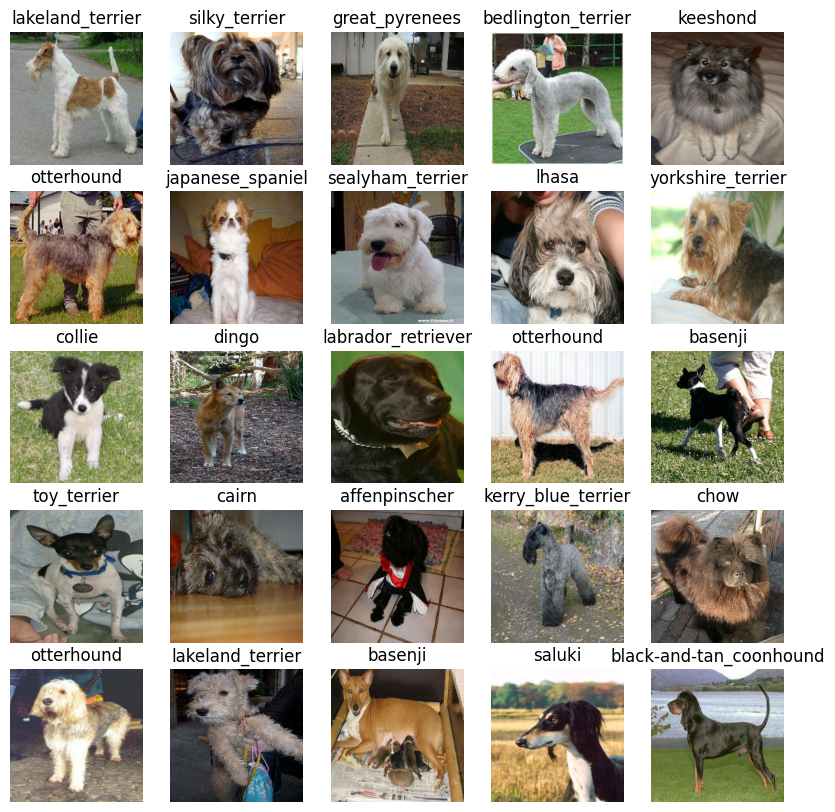

In [ ]:
# visualiz training images from the training data batch
train_images, train_labels = next(train_data.as_numpy_iterator())
show_batch_images(train_images, train_labels)

# The train images keep changing in the output,
# as the train data is shuffled

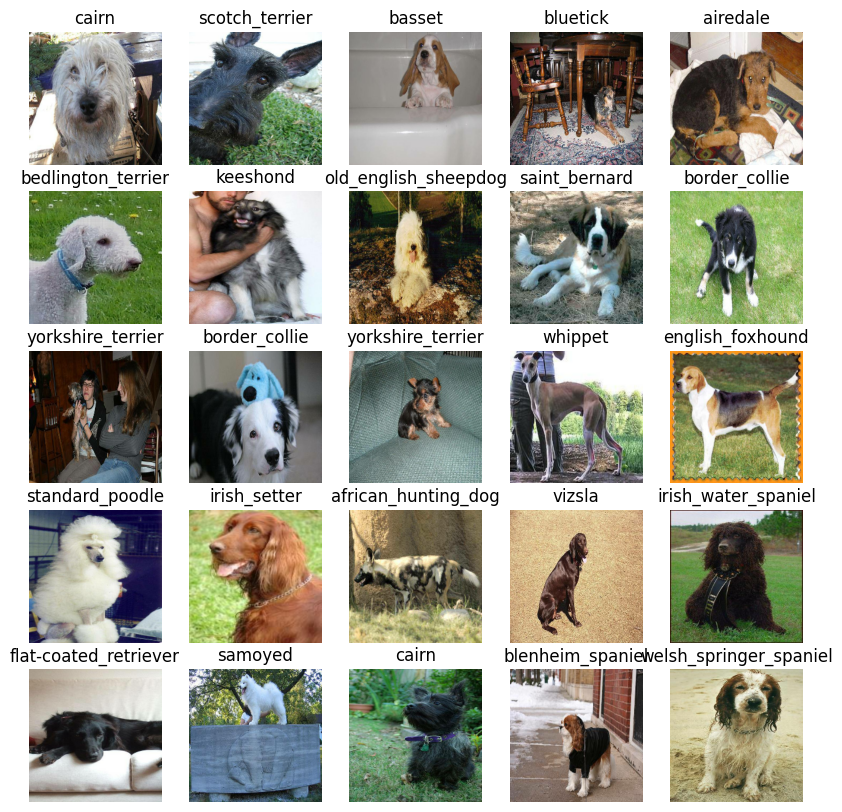

In [ ]:
# visualize validation images from the validation data batch
val_images, val_labels = next(val_data.as_numpy_iterator())
show_batch_images(val_images, val_labels)

## Creating and trainig a model

Now that the data is ready, we can prepare it for modelling. We'll use an existing model from the [TensorFlow Hub.](https://www.tensorflow.org/hub)

TensorFlow Hub is a resource where you can find pretrained machine learning models for the problem you're working on.

Using a pretrained machine learning model is often referred to as **transfer learning**

## Why use a pretrained model?

Building a machine learning model and trainig it on lots from scratch can be expensive and time consuming.

Transfer learning helps elivate some of these by taking what another model has learned and using that information with your problem.


## Building a model
There are a few things we need to define to build a model:

- The input shape(images in the form of Tensors) to our model.
- The output shape (image labels, in the form of Tensors) of our model.
- The URL of the model we want to use.

These things will be standard practice with whatever machine learning model you use. And because we're using TensorFlow, everything will be in the form of Tensors.

In [ ]:
# setup input shape of the model
INPUT_SHAPE = [None, IMG_SIZE, IMG_SIZE, 3] # batch, height, width, color

# setup output shape of the model
OUTPUT_SHAPE = len(unique_breeds) # number of unique labels

# setup the model URL from TensorFlow Hub
MODEL_URL = 'https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1'


## Keras APIs for building a neural network model



There are many ways of building a model in TensorFlow but one of the best ways to get started is to use [Keras API](https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1)

We can create a model using Keras API by following the steps below:
- Takes the input shape, output shape and the model choosen URL as parameters.
- Defines the layers in a keras model in a sequential fashion.
- Compiles the model(says how it should be evaluated and improved).
- Builds the model(tells it what kind of input shape it'll be getting).
- Returns the model.


In [ ]:
# create a function which builds a Keras model
def create_model(input_shape=INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url=MODEL_URL):
  print("Building model with : ", model_url)

  # setup the model layers
  model = keras.Sequential([
      hub.KerasLayer(MODEL_URL), # Layer 1 (input layer)
      keras.layers.Dense(units=OUTPUT_SHAPE,
                            activation='softmax') # Layer 2 (output layer)
  ])

  # compile the model
  model.compile(
      loss=keras.losses.CategoricalCrossentropy(), # The model should reduce this(how wrong its guesses are)
      optimizer=keras.optimizers.Adam(), # something that tells the model how to improve its guesses
      metrics=['accuracy'] # This should be high for a model that is performing well
  )

  # Build the model
  model.build(INPUT_SHAPE)

  return model

## Setting up the model layers

There are 2 ways to do this in Keras, the functional and Sequential API. We've used the sequential.

The Keras documentation states the functional API is the way to go for defining complex models but the Sequential API(a linear stack of layers) is fine for getting started, which is what we're doing

The first layer we use is the model from TensorFlow Hub `hub.KerasLayer(MODEL_URL)`. S our first laye ris actually an entire model(many more layers). This input layer takes in our images and finds patters in them based on the patterns  `mobilenet_v2_130_224` has found.

The `activation="softmax"` parameter tells the output layer, we'd like to assign a probability value to each of the 120 labels somewhere between 0 & 1. The higher the value, the more the model believes the input image should have that label. If we were working on a binary classification problem, we'd use `activation="sigmoid"`.


## Compiling the model

1. `loss` : The height of the hill is the loss function, the models goal is to minize this, getting to 0(the bottom of the hill) means the model is learning perfectly.

2. `optimizer`: Your friend Adam is the optimizer, he's the one telling you how to navigate the hill (lower the loss function) based on what you've done so far. His name is Adam because the [Adam optimizer](https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/) is a great general which performs well on most models. Other optimizers include RMSprop and Stochastic Gradient Descent.

3. `metrics` - This is the onlooker at the bottom of the hill rating how well your perfomance is. Or in our case, giving the accuracy of how well our model is predicting the correct image label

In [ ]:
# building the model

model = create_model()
model.summary()

Building model with :  https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1001)              5432713   
                                                                 
 dense (Dense)               (None, 120)               120240    
                                                                 
Total params: 5552953 (21.18 MB)
Trainable params: 120240 (469.69 KB)
Non-trainable params: 5432713 (20.72 MB)
_________________________________________________________________


The non-trainable parameters are the patterns learned by mobilenet_v2_130_224 and the trainable parameters are the ones in the dense layer we added.

This means the main bulk of the information in our model has already been learned and we're going to take that and adapt it to our own problem.

## Creating callbacks

Callbacks are helper functions a model can use during training to do things such as save a models progress, check a models progress or stop early if a model stops improving.

The 2 callbacks we're going to add are a TensorBoard callback and an Early Stopping Callback.

## TensorBoard Callback

It helps provide a visual way to monitor the progress of the model during and after training.

It can be used directly in a noteback to track the performance measures of a model such as loss and accuracy.

To setup a TensorBoard callback and view TensorBoard in a notebook, we need to do 3 things:

- Load the TensorBoard notebook extension.
- Create a TensorBoard callback which is able to save logs to a directory and pass it to our model's `fit()` function.
- Visualize the models training logs using `%tensorboard` magic function.



In [ ]:
%load_ext tensorboard

In [ ]:
import datetime

# create a function to build a TensorBoard callback
def create_tensorboard_callback():
  # create a log direcotry for storing TensorBoard logs
  logdir = os.path.join('drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/logs',
                        # make it so the logs get tracked whenever we run an experiment)
                        datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
  return keras.callbacks.TensorBoard(logdir)

## Early Stopping Callback

It helps prevent overfitting by stopping a model when a certain evaluation metric stops improving. If a model trains for too long, it can do so well at finding patterns in a certain dataset that it's not able to use those patterns on the another dataset it hasn't seen before(doesn't generalize).



In [ ]:
# Create early stopping(once the model stops improving, stop training)
early_stopping = keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                               patience=3) # stops after 3 rounds of no improvements

## Trainig a model (on a subset of data)

Our first model is only going to be trained on 1000 images. Or trained on 800 images and then validated on 200 images, meaning 1000 images total or about 10% of the total data.

We do this to make sure everything is working, And if it is, we can step it up later and train on the entire training dataset.

The final parameter we'll define before training is `NUM_EPOCHS` (also known as number of epochs).

`NUM_EPOCHS` defines how many passes of the data we'd like the model to do, A pass is equivalent to the model trying to find patterns in each dog images and see which patterns relate to each label.

If `NUM_EPOCHS=1`, the model will only look at the data once and will probably score badly because it hasn't had a chance to correct itself.It would be like you competing in the international hill descent championships and your friend Adam only being able to give you 1 single instruction to get down the hill.

What's a good value for NUM_EPOCHS?

This one is hard to say. 10 could be a good start but so could 100. This is one of the reasons we created an early stopping callback. Having early stopping setup means if we set NUM_EPOCHS to 100 but our model stops improving after 22 epochs, it'll stop training.


In [ ]:
# check again if GPU is available
print('GPU', 'YES :))' if tf.config.list_logical_devices('GPU') else 'NO :((')

GPU YES :))


In [ ]:
NUM_EPOCHS = 100

Let's create a simple function which trains a model. The function will:

- Create a model using `create_model()`.
- Setup a TensorBoard callback using `create_tensorboard_callback()` (we do this here so it creates a log directory of the current date and time).
- Call the fit() function on our model passing it the training data, validatation data, number of epochs to train for and the callbacks we'd like to use.
- Return the fitted model.


In [ ]:
# build a function to train and return a trained model

def train_model():
  # create a model
  model = create_model()

  # create new TensorBoard session everytime we train a model
  tensorboard = create_tensorboard_callback()

  # fit the model to the data passing it the callback we created
  model.fit(x=train_data,
            epochs=NUM_EPOCHS,
            validation_data=val_data,
            validation_freq=1,  # check validation metrics every epoch
            callbacks=[tensorboard, early_stopping])

  return model

Note: When training a model for the first time, the first epoch will take a while to load compared to the rest. This is because the model is getting ready and the data is being initialised. Using more data will generally take longer, which is why we've started with ~1000 images. After the first epoch, subsequent epochs should take a few seconds.

In [ ]:
# fit the model to the data
model = train_model()

Building model with :  https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1
Epoch 1/100
25/25 [==============================] - 178s 7s/step - loss: 4.5344 - accuracy: 0.0988 - val_loss: 3.3936 - val_accuracy: 0.2750
Epoch 2/100
25/25 [==============================] - 3s 110ms/step - loss: 1.6049 - accuracy: 0.6938 - val_loss: 2.1793 - val_accuracy: 0.5050
Epoch 3/100
25/25 [==============================] - 3s 110ms/step - loss: 0.5603 - accuracy: 0.9388 - val_loss: 1.6842 - val_accuracy: 0.6050
Epoch 4/100
25/25 [==============================] - 3s 110ms/step - loss: 0.2519 - accuracy: 0.9900 - val_loss: 1.4809 - val_accuracy: 0.6350
Epoch 5/100
25/25 [==============================] - 4s 168ms/step - loss: 0.1441 - accuracy: 1.0000 - val_loss: 1.3952 - val_accuracy: 0.6650
Epoch 6/100
25/25 [==============================] - 3s 109ms/step - loss: 0.0979 - accuracy: 1.0000 - val_loss: 1.3466 - val_accuracy: 0.6700
Epoch 7/100
25/25 [==================

## Checking the TensorBoard Logs

We can check the performance of the trained model by visualizing the TensorBoard logs

The TensorBoard magic function (`tensorboard`) will access the logs directory we created earilier and visualize its contents



In [ ]:
# %load_ext tensorboard
%tensorboard  --logdir drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/logs

UsageError: Line magic function `%tensorboard` not found.


## Making an evaluating predictions using a trained model

Making predictions with a trained model is calling `predict()` on it and passing it data in the same format the was trained on.



In [ ]:
predictions = model.predict(val_data, verbose=1)
predictions

7/7 [==============================] - 1s 90ms/step


array([[5.9823570e-04, 1.2485722e-04, 8.8009756e-04, ..., 8.4065186e-04,
        5.0997547e-05, 1.9542666e-03],
       [1.4657755e-03, 5.7363731e-04, 2.5732640e-02, ..., 1.2950989e-03,
        1.5188417e-03, 9.2329701e-06],
       [3.3311023e-06, 5.2210639e-06, 2.0651070e-05, ..., 1.3617656e-05,
        9.5358128e-06, 3.3584281e-05],
       ...,
       [4.2743090e-06, 2.8041242e-05, 3.6116959e-05, ..., 2.5479960e-05,
        2.2602848e-04, 6.1731545e-05],
       [4.0499871e-03, 8.9368412e-05, 1.0031674e-04, ..., 2.0541735e-04,
        1.3699374e-04, 5.3592860e-03],
       [5.9164508e-04, 4.9958062e-06, 8.9837599e-04, ..., 1.8454604e-03,
        1.9050759e-04, 7.8735438e-06]], dtype=float32)

In [ ]:
# check the shape of predictions
predictions.shape

(200, 120)

Making prediction with the model returns an array with a different value for each label.

In this case, making predictions on the validation data (200 images) returns an array `(predictions)` of arrays, each containing 120 different values (one for each unique dog breed).

These different values are the probablitites or the likelihood the model has predicted a certain image a certain breed of dog. The higher the value, the more likely the model thinks a given image is a specific breed of dog.



In [ ]:
# first prediction
index = 0
print(predictions[index])
print(f'Max value (probablity of prediction): {np.max(predictions[index])}')
print(f"Sum :{np.sum(predictions[index])}")
print(f"Max Index: {np.argmax(predictions[index])}")
print(f"Predicted label: {unique_breeds[np.argmax(predictions[index])]}")


[5.9823570e-04 1.2485722e-04 8.8009756e-04 4.5637137e-04 2.5686930e-04
 1.5524078e-04 2.1283992e-02 7.6118059e-04 2.1789239e-04 2.6922766e-04
 3.2472776e-04 6.3420033e-05 2.4643419e-03 1.8102680e-04 1.9161880e-04
 4.1924324e-04 1.9418584e-04 1.0855677e-01 1.5624586e-05 5.7115747e-05
 1.2289963e-03 1.6471231e-05 1.1468765e-05 9.7164663e-04 9.2052884e-05
 2.2115228e-04 3.0063087e-01 4.7256556e-04 1.0459119e-03 1.2053214e-04
 3.0163023e-05 1.2477707e-03 2.3603213e-03 1.4507753e-05 2.1406898e-04
 3.7534256e-02 3.2679076e-05 6.0077764e-05 4.0198665e-05 1.4332819e-04
 3.3611711e-04 4.2597127e-05 1.0101681e-03 1.2671693e-04 1.2432022e-05
 2.4191559e-04 2.8703033e-05 2.3951575e-04 1.0336897e-04 3.6902889e-04
 1.9485365e-04 2.8105003e-05 1.6801849e-04 1.1669237e-04 3.7483184e-04
 7.6290147e-05 5.5989072e-05 2.6627330e-03 1.0877028e-04 2.0133562e-01
 4.6730460e-05 1.9502924e-05 8.5080706e-04 4.5209123e-05 1.6563918e-04
 3.6824923e-02 9.1076025e-04 3.3730379e-04 3.2073532e-03 7.9969919e-05
 9.713

Let's build functions to compare the predicted data to the true labels and original image

In [18]:
# turn prediction probablitites into their respective label
def get_pred_label(prediction_probabilties):
  """
  Turns an array of prediction probabilties into a label
  """

  return unique_breeds[np.argmax(prediction_probabilties)]



In [ ]:
# get a predicted label based on an array of prediction probabilities
pred_label = get_pred_label(predictions[0])
pred_label

'cairn'

Let's use the validated_data images to visually compare the models predictions with the validation labels.

Since the val data is in batch form, to get a list of validation images and labels, we'll have to unbatch it using `(unbatch)` and then turn it into an iterator using `as_numpy_iterator()`

In [ ]:
# create a function to unbatch a batched data
def unbatchify(data):
  """
  Takes a batched dataset of (image, label) Tensors and returns
  separated arrays of images and labels
  """

  images, labels = [], []
  # loop through unbatched data
  for image, label in data.unbatch().as_numpy_iterator():
    images.append(image)
    labels.append(unique_breeds[np.argmax(label)])
  return images, labels


In [ ]:
# unbatchify the validation data
val_images, val_labels = unbatchify(val_data)
val_images[0], val_labels[0]

(array([[[0.29599646, 0.43284872, 0.3056691 ],
         [0.26635826, 0.32996926, 0.22846507],
         [0.31428418, 0.27701408, 0.22934894],
         ...,
         [0.77614343, 0.82320225, 0.8101595 ],
         [0.81291157, 0.8285351 , 0.8406944 ],
         [0.8209297 , 0.8263737 , 0.8423668 ]],
 
        [[0.2344871 , 0.31603682, 0.19543913],
         [0.3414841 , 0.36560842, 0.27241898],
         [0.45016077, 0.40117094, 0.33964607],
         ...,
         [0.7663987 , 0.8134138 , 0.81350833],
         [0.7304248 , 0.75012016, 0.76590735],
         [0.74518913, 0.76002574, 0.7830809 ]],
 
        [[0.30157745, 0.3082587 , 0.21018331],
         [0.2905954 , 0.27066195, 0.18401104],
         [0.4138316 , 0.36170745, 0.2964005 ],
         ...,
         [0.79871625, 0.8418535 , 0.8606443 ],
         [0.7957738 , 0.82859945, 0.8605655 ],
         [0.75181633, 0.77904975, 0.8155256 ]],
 
        ...,
 
        [[0.9746779 , 0.9878955 , 0.9342279 ],
         [0.99153054, 0.99772066, 0.94278

Let's create functions to visulaize the predictions with images and labels

The first function we'll create will:

* Take an array of prediction probabilites, an array of truth labels, an array of images and an integer.
* Convert the prediction probabilties to a predicted label.
* Plot the predicted label, its predicted probability, the truth label and target image on a single plot.


In [ ]:
def plot_pred(pred_probs, labels, images, n=1):
  """
  View the prediction, ground truth label and image for sample n
  """

  pred_prob, true_label, image = pred_probs[n], labels[n], images[n]

  # get the pred label
  pred_label = get_pred_label(pred_prob)

  # plot image and remove ticks
  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  # change the title color depending on if the prediction ins right or wrong
  if pred_label == true_label:
    color = 'green'
  else:
    color = 'red'

  plt.title("{} {:2.0f}% ({})".format(pred_label,
                                      np.max(pred_prob)*100,
                                      true_label),
            color=color)

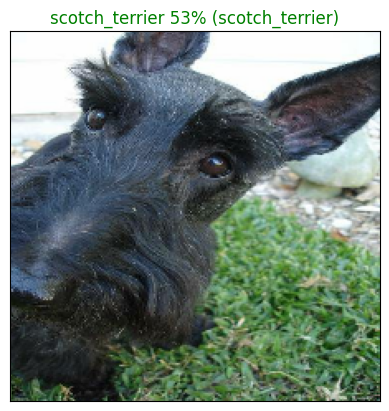

In [ ]:
# view an example prediction, original image and truth label
plot_pred(pred_probs=predictions,
          labels=val_labels,
          images=val_images)

Since we're working with a multi-class problem (120 different dog breeds), it would also be good to see what other guesses our model is making. More specifically, if our model predicts a certain label with 24% probability, what else did it predict?

Let's build a function to demonstrate. The function will:

- Take an input of a prediction probabilities array, a ground truth labels array and an integer.
- Find the predicted label using get_pred_label().
- Find the top 10:
  - Prediction probabilities indexes
  - Prediction probabilities values
  - Prediction labels
- Plot the top 10 prediction probability values and labels, coloring the true label green.

In [ ]:
def plot_pred_conf(prediction_probabilities, labels, n=1):
  """
  Plots the top 10 highes prediction confidences along
  with the truth labels for samples n.
  """

  pred_prob, true_label = prediction_probabilities[n], labels[n]

  # get the predicted label
  pred_label = get_pred_label(pred_prob)

  # find the top 10 prediction confidence indexes
  top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]
  # find the top 10 prediction confidence values
  top_10_pred_values = pred_prob[top_10_pred_indexes]
  # find the top 10 prediction labels
  top_10_pred_labels = unique_breeds[top_10_pred_indexes]

  # setup plot
  top_plot = plt.bar(np.arange(len(top_10_pred_labels)),
                     top_10_pred_values,
                     color='grey')
  plt.xticks(np.arange(len(top_10_pred_labels)),
             labels=top_10_pred_labels,
             rotation='vertical')

  # change color of true label
  if np.isin(true_label, top_10_pred_labels):
    top_plot[np.argmax(top_10_pred_labels == true_label)].set_color('green')
  else:
    pass


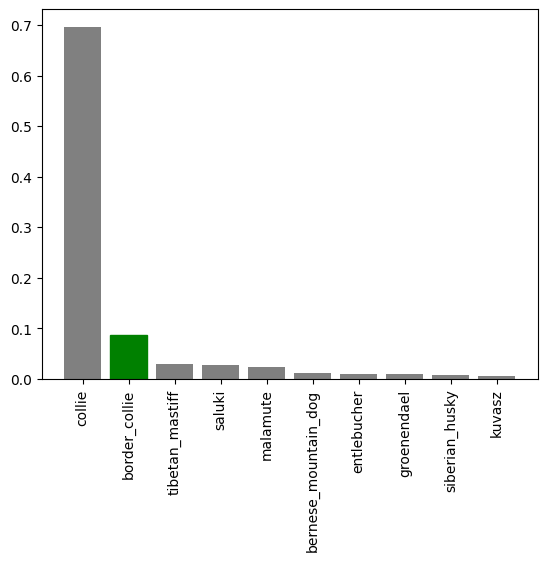

In [ ]:
plot_pred_conf(prediction_probabilities=predictions,
               labels=val_labels,
               n=9)

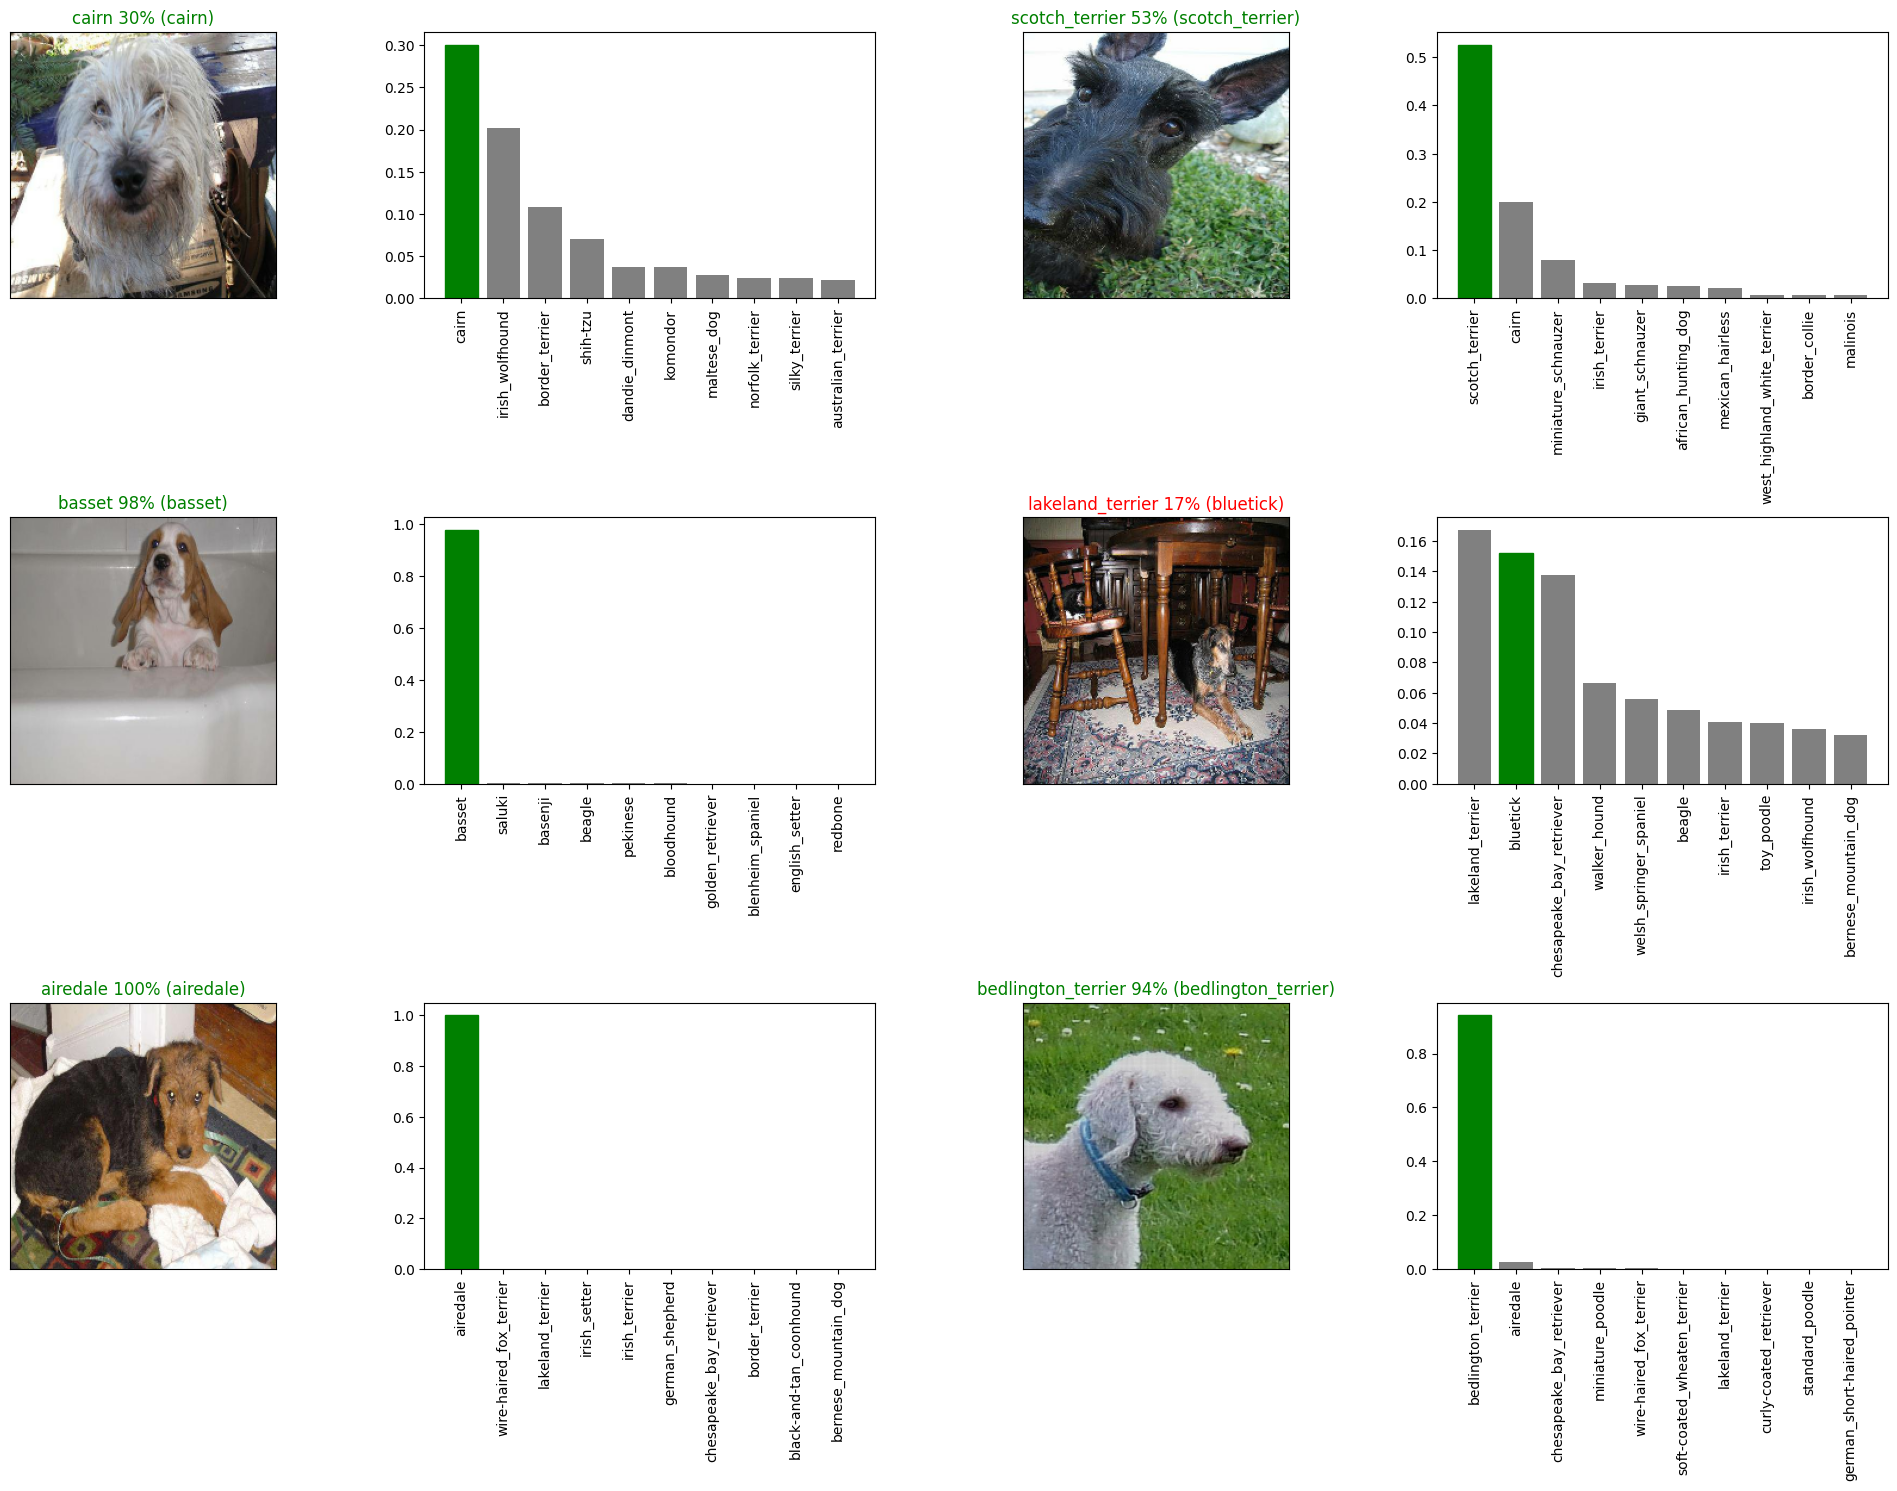

In [ ]:

# Let's check a few predictions and their different values
i_multiplier = 0
num_rows = 3
num_cols = 2
num_images = num_rows*num_cols
plt.figure(figsize=(5*2*num_cols, 5*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_pred(pred_probs=predictions,
            labels=val_labels,
            images=val_images,
            n=i+i_multiplier)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_pred_conf(prediction_probabilities=predictions,
                labels=val_labels,
                n=i+i_multiplier)
plt.tight_layout(h_pad=1.0)
plt.show()

## Saving and reloading a model

Let's create functions to save and reload a trained model


In [ ]:
def save_model(model, suffix=None):
  """
  Saves a given model in a models directory and appends
  a suffix(str)
  """

  # create a model directory with current time
  modeldir = os.path.join('drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models',
                          datetime.datetime.now().strftime('%Y%m%d-%H%M%S'))
  model_path = modeldir + "-" + suffix + ".h5" # save format of model
  print(f"Saving model to : {model_path}")
  model.save(model_path)
  return model_path

In [13]:
def load_model(model_path):
  """
  Loads a saved model from a specified path.
  """
  print(f"Loading saved model from : {model_path}")
  model = keras.models.load_model(model_path,
                                  custom_objects={'KerasLayer':hub.KerasLayer})
  return model

In [ ]:
# Save the model trained on 1000 images
save_model(model, suffix='1000-images-dog-vision-model')


Saving model to : drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models/20260920-154755-1000-images-dog-vision-model.h5


/usr/local/lib/python3.13/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models/20260920-154755-1000-images-dog-vision-model.h5'

In [ ]:
# load the saved model
model_1000_images = load_model('drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models/20260829-173206-1000-images-dog-vision-model.h5')

Loading saved model from : drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models/20260829-173206-1000-images-dog-vision-model.h5


Compare the 2 model(the original and loaded one). We can do so by using the `evaluate()` method

In [ ]:
# evaluate the pre-saved model
model.evaluate(val_data)

7/7 [==============================] - 1s 78ms/step - loss: 1.2049 - accuracy: 0.7100


[1.2048646211624146, 0.7099999785423279]

In [ ]:
# evalute the loaded model
model_1000_images.evaluate(val_data)

7/7 [==============================] - 1s 77ms/step - loss: 1.2055 - accuracy: 0.7000


[1.2055224180221558, 0.699999988079071]

## Training a model (on the full data)



In [ ]:
len(X), len(y)

(10222, 10222)

In [ ]:
# create a training data batch for the full training data
full_data = create_data_batches(X, y)

Creating training data batches


In [ ]:
# instantiate a new model for training on the full dataset

full_model = create_model()

Building model with :  https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1


In [ ]:
# create full model callbacks
# TensorBoard callback
full_model_tensorboard = create_tensorboard_callback()

# early stopping callback
full_model_early_stopping = keras.callbacks.EarlyStopping(monitor='accuracy',
                                                          patience=3)


In [ ]:
%tensorboard --logdir drive/My\ Drive/Data/logs

**Note** : Running the cell below will cause the model to train on the full training data(10000+) images, it may take a long time to get started and finish.

The first epoch is always the longest as the data gets loaded into memory. After it's there, it'll speed up.


In [ ]:
# fit the full model to the full training data

full_model.fit(x=full_data,
               epochs=NUM_EPOCHS,
               callbacks=[full_model_tensorboard,
                         full_model_early_stopping])

# save the model after the full training so that it can be
# used later again, instead of re-training the model
# on the full data
full_model_saved_path = save_model(full_model, suffix='full-dog-vision')


Epoch 1/100
320/320 [==============================] - 43s 131ms/step - loss: 0.0209 - accuracy: 0.9986
Epoch 2/100
320/320 [==============================] - 31s 97ms/step - loss: 0.0190 - accuracy: 0.9983
Epoch 3/100
320/320 [==============================] - 34s 105ms/step - loss: 0.0181 - accuracy: 0.9984
Epoch 4/100
320/320 [==============================] - 31s 97ms/step - loss: 0.0142 - accuracy: 0.9990
Epoch 5/100
320/320 [==============================] - 31s 97ms/step - loss: 0.0135 - accuracy: 0.9988
Epoch 6/100
320/320 [==============================] - 33s 102ms/step - loss: 0.0130 - accuracy: 0.9987
Epoch 7/100
320/320 [==============================] - 31s 98ms/step - loss: 0.0107 - accuracy: 0.9990
Saving model to : drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models/20260920-171051-full-dog-vision.h5


In [14]:
# loading the presaved full model
saved_full_model = load_model('drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models/20260920-171051-full-dog-vision.h5')

Loading saved model from : drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/models/20260920-171051-full-dog-vision.h5


## Making predictions on the test dataset

To make predictions on the test data:

- Get the test image filenames.
- Convert the filenames into test data batches using `create_data_batches()` and setting the test_data parameter to True.
- Make a predictions array by passing the test data batches to the `predict()` function.


In [ ]:
test_path = 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/'
test_filenames = [test_path + fname for fname in os.listdir(test_path)]
test_filenames[:10]

['drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/e64296ffbae301f86c8728834c507cb6.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/e278b2f68fa5d146e0bf06eee5faa0e3.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/ddf4f1d39b7ebc610ff479396cd9c6fc.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/e119301e11d4f1620948c3e6f5a3f021.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/df4b040b13c5f514d215ba7c0813eaf8.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/e36ec4ab8218060660ec82fd6c4757a7.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/e18fbb12037c297b90642e99073cd6b4.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/e596c0d97b381e876d46dda2eb60074c.jpg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/e380bd4f8375d09ae72f4f36aa61003

In [ ]:
len(test_filenames)

10357

In [ ]:
# create a test data batch
test_data = create_data_batches(test_filenames, test_data=True)


Creating test data batches...


In [ ]:
# make predictions on the test data batch using the loaded full model
test_predictions = saved_full_model.predict(test_data,
                                            verbose=1)

  3/324 [..............................] - ETA: 45:16

In [ ]:
# check out the test predictions
test_predictions[:10]

array([[4.48067876e-05, 2.35877131e-08, 3.01622975e-08, ...,
        2.73795735e-07, 7.21949167e-10, 2.57407891e-08],
       [6.90665503e-04, 7.42255315e-06, 2.56157651e-10, ...,
        5.96607052e-12, 5.20719448e-12, 9.84383702e-01],
       [1.92243579e-06, 3.82324145e-10, 2.78925438e-09, ...,
        6.40148282e-05, 5.65656890e-08, 4.79521404e-04],
       ...,
       [1.57854210e-08, 2.80246741e-06, 1.17894115e-11, ...,
        9.75174608e-10, 2.27911645e-09, 6.32985192e-11],
       [1.34316434e-08, 4.13281320e-08, 9.71607594e-09, ...,
        1.47829908e-07, 2.38602825e-05, 8.14498776e-07],
       [1.83074633e-09, 1.49290608e-10, 2.00414934e-13, ...,
        1.47911859e-12, 2.62619864e-08, 1.07185700e-08]], dtype=float32)

## Preparing test dataset predictions for kaggle

To get the data in the format, we'll:

- Create a pandas DataFrame with an ID column as well as a column for each dog breed.
- Add data to the ID column by extracting the test image ID's from their filepaths.
- Add data(the prediction probabililties) to each of the dog breed columns using the`unique_labels` list and the `test_predictions` list.
- Export the DataFrame as a CSV to submit to Kaggle.


In [ ]:
# Create pandas DataFrame with empty columns
preds_df = pd.DataFrame(columns=['id'] + list(unique_breeds))
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier


In [ ]:
# Append test image ID's to the predictions DataFrame
test_path = 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/test/'
preds_df['id'] = [os.path.splitext(path)[0] for path in os.listdir(test_path)]
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,e64296ffbae301f86c8728834c507cb6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,e278b2f68fa5d146e0bf06eee5faa0e3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ddf4f1d39b7ebc610ff479396cd9c6fc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,e119301e11d4f1620948c3e6f5a3f021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,df4b040b13c5f514d215ba7c0813eaf8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Add the prediction probabilities to each dog breed column
preds_df[list(unique_breeds)] = test_predictions
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,e64296ffbae301f86c8728834c507cb6,4.480679e-05,2.358771e-08,3.016230e-08,7.495817e-08,1.282921e-09,2.406721e-08,4.230303e-09,5.154576e-12,6.199747e-12,...,1.818296e-13,9.868204e-12,8.989260e-10,1.204892e-05,2.845958e-09,1.576282e-11,3.994695e-09,2.737957e-07,7.219492e-10,2.574079e-08
1,e278b2f68fa5d146e0bf06eee5faa0e3,6.906655e-04,7.422553e-06,2.561577e-10,1.524382e-11,5.332646e-14,5.324945e-13,1.811677e-08,1.434028e-10,7.141981e-11,...,5.720272e-08,4.324046e-11,5.692219e-10,6.683620e-08,5.196838e-11,1.102897e-08,1.828556e-09,5.966071e-12,5.207194e-12,9.843837e-01
2,ddf4f1d39b7ebc610ff479396cd9c6fc,1.922436e-06,3.823241e-10,2.789254e-09,3.423964e-09,1.084329e-10,1.826217e-05,7.304743e-07,3.443357e-02,5.531680e-07,...,1.542788e-04,4.201991e-03,8.025124e-09,4.575485e-08,1.094903e-04,9.925033e-04,5.221109e-06,6.401483e-05,5.656569e-08,4.795214e-04
3,e119301e11d4f1620948c3e6f5a3f021,4.979735e-09,2.759758e-11,3.549660e-11,1.988279e-02,3.745637e-07,2.484020e-11,6.467057e-10,5.675656e-10,2.948585e-12,...,2.058705e-05,3.246632e-08,3.425028e-08,1.250340e-08,7.434060e-10,1.029605e-08,4.074663e-10,1.413549e-09,2.402098e-07,1.662054e-05
4,df4b040b13c5f514d215ba7c0813eaf8,1.203098e-10,3.203385e-08,5.368531e-11,1.526717e-15,6.019750e-13,6.012731e-12,3.610642e-10,1.729972e-13,1.223490e-10,...,4.695525e-09,1.435531e-11,4.991641e-10,2.033402e-11,2.118550e-10,2.878416e-15,1.112351e-09,5.206620e-13,7.284461e-11,5.494635e-08


In [ ]:
# Export the predictions DataFrame to CSV to submit to Kaggle
preds_df.to_csv('drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/full_model_submission_1_mobilenetV2.csv',
                index=False)


## Making predictions on custom images

To do so we'll:
- Get the filepaths of our own images.
- Turn the filepaths into data batches using `create_data_batches()`. And since the custom images won't have labels, we set the test_data paramater to True.
- Pass the custom image data batch to our model's `predict()` method.
- Convert the prediction output probabilities to prediction labels.
- Compare the predicted labels to the custom images.


In [2]:
import os

custom_path = 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/'
custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]
custom_image_paths

['drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/12345rewq12345.jpeg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/567890plkmjy567890.jpeg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/12wedcvgt56yuhjnju.jpeg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/rfvbhtg12345.jpeg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/rfgvbgtghnhyh12345.jpeg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/human-with-dog.jpeg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/1qazxsw23edc.jpeg',
 'drive/MyDrive/UDEMY-DATASCIENCE-NOTES/Projects/deep_learning/Data/custom_data/Indie-Dog-Indian-Pariah-Dog-Nature-Benefits-Adoption-Guide-rmde3bhozkxlyccebtpudy43s0ysyqvkudjskpaohc.jpeg']

In [10]:
# Turn custom images into data batches
custom_data = create_data_batches(custom_image_paths, test_data=True)
custom_data

Creating test data batches...


<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

In [38]:
# make predictions on the custom data
print("Shape:", image.shape)
print("Dtype:", image.dtype)
print("Min:", tf.reduce_min(image).numpy())
print("Max:", tf.reduce_max(image).numpy())
print("Mean:", tf.reduce_mean(image).numpy())
custom_preds = saved_full_model.predict(custom_data)
custom_preds.shape

pred = custom_preds[4]
top5 = np.argsort(pred)[-5:][::-1]
for i in top5:
    print(unique_breeds[i], pred[i])

Shape: (224, 224, 3)
Dtype: float32
Min: 0.003921569
Max: 0.97240907
Mean: 0.59590805
1/1 [==============================] - 0s 194ms/step
shih-tzu 0.44523725
japanese_spaniel 0.3644937
chihuahua 0.17724355
yorkshire_terrier 0.0062428177
papillon 0.0046662996


In [26]:
# get the custom image prediction labels
custom_pred_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]
custom_pred_labels

['french_bulldog',
 'labrador_retriever',
 'maltese_dog',
 'maltese_dog',
 'shih-tzu',
 'maltese_dog',
 'shih-tzu',
 'ibizan_hound']

In [27]:
# Get custom images
custom_images = []
# loop through unbatches data
for image in custom_data.unbatch().as_numpy_iterator():
  custom_images.append(image)


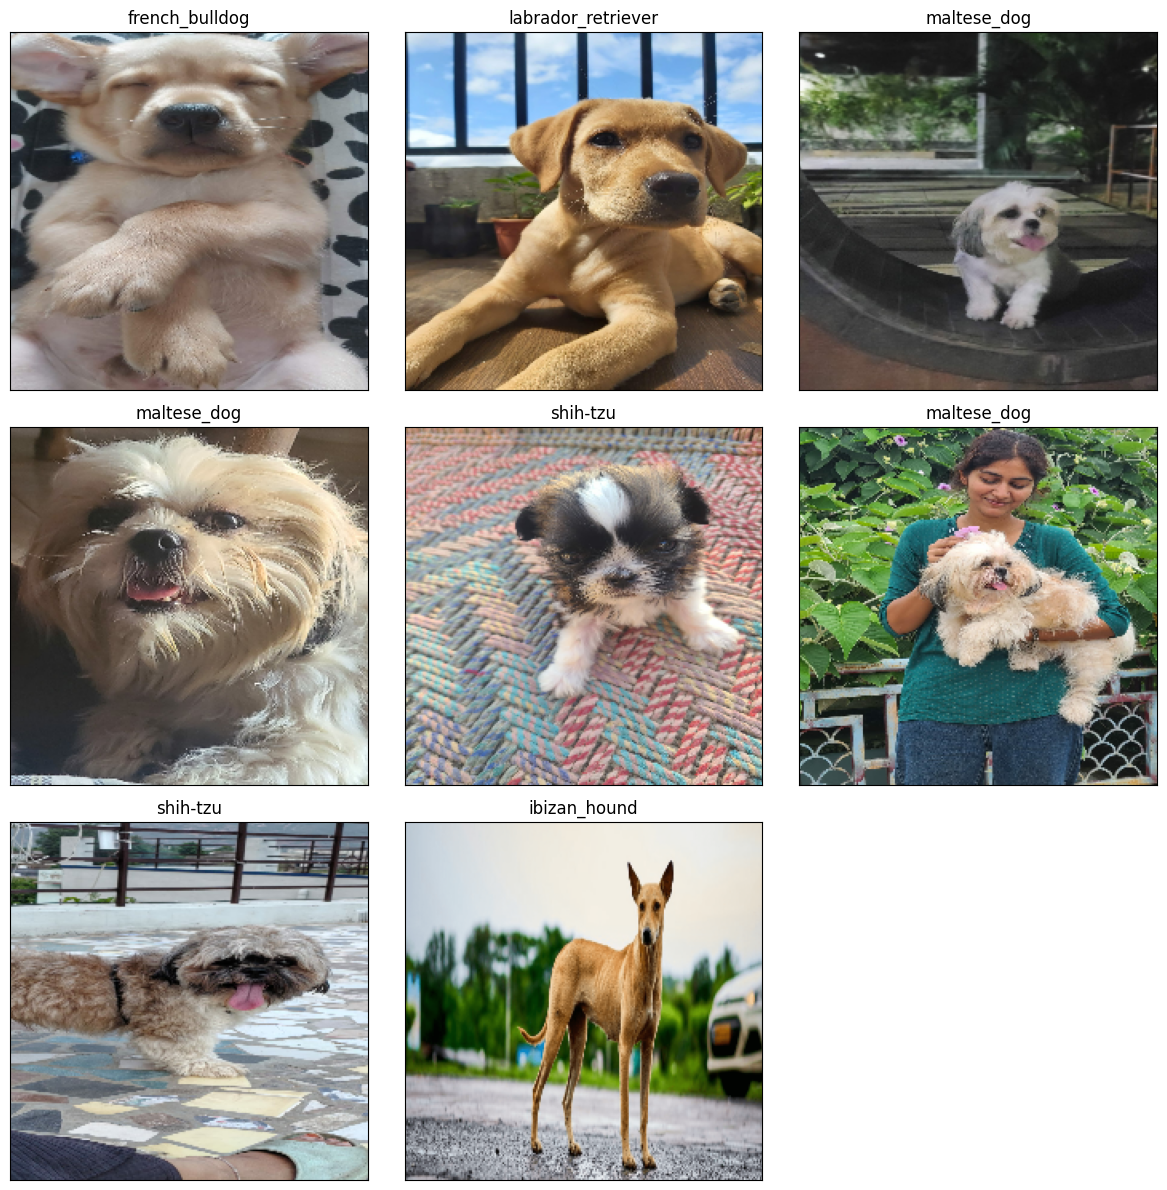

In [35]:
import math

num_images = len(custom_images)
cols = 3
rows = math.ceil(num_images / cols)

plt.figure(figsize=(12, 4 * rows))

for i, image in enumerate(custom_images):
    plt.subplot(rows, cols, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.title(custom_pred_labels[i])
    plt.imshow(image)

plt.tight_layout()